# Análisis exploratorio – Alerta académica

Este notebook explora el dataset sintético `data/entrada/estudiantes.csv`:

1. Resumen de los datos.
2. Relación entre horas de estudio y nota final.
3. Comparación entre un ajuste lineal y uno cuadrático.
4. Distribución de las notas respecto al umbral aprobatorio (60).

> Abre el notebook desde la raíz del proyecto (`alerta_academica/`) con el entorno `alerta_academica` activo.
> La primera celda de código contiene toda la configuración (librerías, constantes, estilo y carga de `df`).
> Cada celda posterior incluye una verificación de seguridad autocontenida, así que puede ejecutarse
> de forma independiente, incluso después de reiniciar el kernel.

In [13]:
# ===================== CONFIGURACIÓN DEL NOTEBOOK =====================
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score

# --- Rutas: funcionan desde la raíz del proyecto (alerta_academica/) ---
RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RUTA_CSV = RAIZ / "data" / "entrada" / "estudiantes.csv"

# --- Constantes globales ---
NOTA_APROBATORIA = 60
COLUMNAS_REQUERIDAS = ["id_estudiante", "horas_estudio", "asistencia_pct",
                       "tareas_entregadas", "nota_final", "estado"]
COLORES_ESTADO = {"aprobado": "#2a78d6", "en_riesgo": "#eb6834"}
COLOR_LINEAL = "#1baf7a"
COLOR_CUADRATICO = "#6250d6"
COLOR_UMBRAL = "#52514e"
COLOR_NEUTRO = "#9c9b95"

# --- Estilo de gráficos: ejes y rejilla discretos ---
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#52514e",
    "axes.labelcolor": "#0b0b0b",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e5e4df",
    "grid.linewidth": 0.8,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "legend.frameon": False,
})

# --- Si el CSV aún no existe (no se ejecutó main.py), se genera ---
if not RUTA_CSV.exists():
    sys.path.insert(0, str(RAIZ))
    from src.datos import crear_csv
    crear_csv(n=40, semilla=42)

# --- Cargar y verificar los datos de entrada ---
df = pd.read_csv(RUTA_CSV, encoding="utf-8")

faltantes = [c for c in COLUMNAS_REQUERIDAS if c not in df.columns]
if faltantes:
    raise ValueError(f"Faltan columnas requeridas: {faltantes}")
if df.empty:
    raise ValueError("El CSV no contiene registros.")
if not df["nota_final"].between(0, 100).all():
    raise ValueError("Hay notas fuera del rango 0-100.")

print(f"Datos cargados correctamente. Total de registros: {len(df)}")
print(f"Archivo: {RUTA_CSV}")
print(df.head())

Datos cargados correctamente. Total de registros: 40
Archivo: E:\senati\alerta_academica\data\entrada\estudiantes.csv
  id_estudiante  horas_estudio  asistencia_pct  tareas_entregadas  nota_final  \
0          E001            9.5              98                  6        92.9   
1          E002            5.8              75                  8        73.1   
2          E003           10.4              62                  8        86.2   
3          E004            8.7              93                  6        82.3   
4          E005            2.0              83                  9        66.2   

     estado  
0  aprobado  
1  aprobado  
2  aprobado  
3  aprobado  
4  aprobado  


## 1. Resumen de los datos

In [15]:
# --- Verificación de seguridad: recrea el entorno si esta celda se ejecuta sola ---
if "df" not in globals() or "COLORES_ESTADO" not in globals():
    from pathlib import Path
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    from sklearn.metrics import r2_score

    NOTA_APROBATORIA = 60
    COLORES_ESTADO = {"aprobado": "#2a78d6", "en_riesgo": "#eb6834"}
    COLOR_LINEAL, COLOR_CUADRATICO = "#1baf7a", "#6250d6"
    COLOR_UMBRAL, COLOR_NEUTRO = "#52514e", "#9c9b95"
    plt.rcParams.update({
        "figure.figsize": (8, 5), "figure.dpi": 110,
        "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#e5e4df", "grid.linewidth": 0.8,
        "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
    })
    RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
    RUTA_CSV = RAIZ / "data" / "entrada" / "estudiantes.csv"
    if not RUTA_CSV.exists():
        raise FileNotFoundError(f"No existe {RUTA_CSV}. Ejecuta la primera celda o 'python main.py'.")
    df = pd.read_csv(RUTA_CSV, encoding="utf-8")

print(df["estado"].value_counts(), "
")
df.describe().round(2)

SyntaxError: unterminated string literal (detected at line 27) (2204099224.py, line 27)

## 2. Relación horas de estudio vs nota final

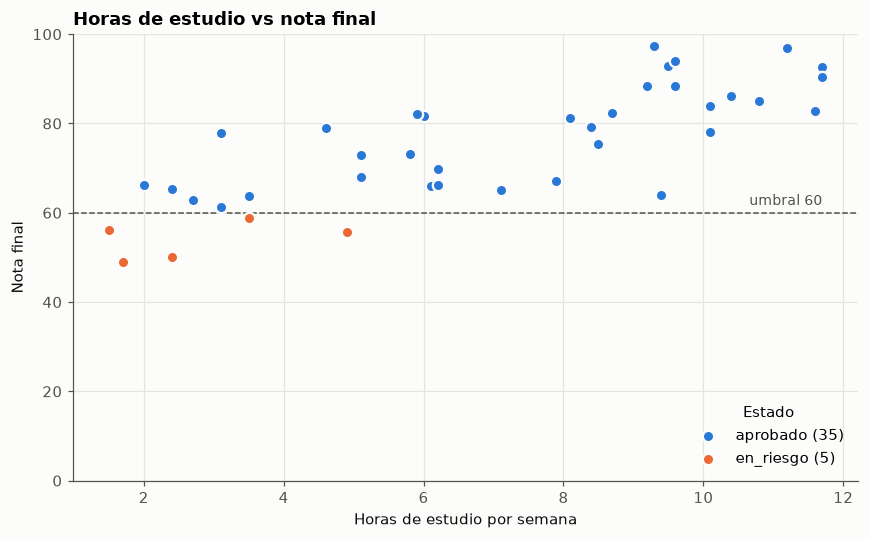

Correlación de Pearson horas–nota: 0.796


In [16]:
# --- Verificación de seguridad: recrea el entorno si esta celda se ejecuta sola ---
if "df" not in globals() or "COLORES_ESTADO" not in globals():
    from pathlib import Path
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    from sklearn.metrics import r2_score

    NOTA_APROBATORIA = 60
    COLORES_ESTADO = {"aprobado": "#2a78d6", "en_riesgo": "#eb6834"}
    COLOR_LINEAL, COLOR_CUADRATICO = "#1baf7a", "#6250d6"
    COLOR_UMBRAL, COLOR_NEUTRO = "#52514e", "#9c9b95"
    plt.rcParams.update({
        "figure.figsize": (8, 5), "figure.dpi": 110,
        "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#e5e4df", "grid.linewidth": 0.8,
        "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
    })
    RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
    RUTA_CSV = RAIZ / "data" / "entrada" / "estudiantes.csv"
    if not RUTA_CSV.exists():
        raise FileNotFoundError(f"No existe {RUTA_CSV}. Ejecuta la primera celda o 'python main.py'.")
    df = pd.read_csv(RUTA_CSV, encoding="utf-8")

fig, ax = plt.subplots()

for estado, grupo in df.groupby("estado"):
    ax.scatter(
        grupo["horas_estudio"], grupo["nota_final"],
        s=55, color=COLORES_ESTADO[estado], edgecolor="#fcfcfb", linewidth=1.5,
        label=f"{estado} ({len(grupo)})", zorder=3,
    )

ax.axhline(NOTA_APROBATORIA, color=COLOR_UMBRAL, linestyle="--", linewidth=1)
ax.text(df["horas_estudio"].max(), NOTA_APROBATORIA + 1, f"umbral {NOTA_APROBATORIA}",
        ha="right", va="bottom", color=COLOR_UMBRAL, fontsize=9)

ax.set_title("Horas de estudio vs nota final", loc="left", fontweight="bold")
ax.set_xlabel("Horas de estudio por semana")
ax.set_ylabel("Nota final")
ax.set_ylim(0, 100)
ax.legend(title="Estado", loc="lower right")
plt.tight_layout()
plt.show()

print(f"Correlación de Pearson horas–nota: {df['horas_estudio'].corr(df['nota_final']):.3f}")

## 3. Ajuste lineal vs cuadrático

Se ajustan polinomios de grado 1 y 2 con `np.polyfit` usando solo las horas de estudio como variable explicativa y se compara su R².

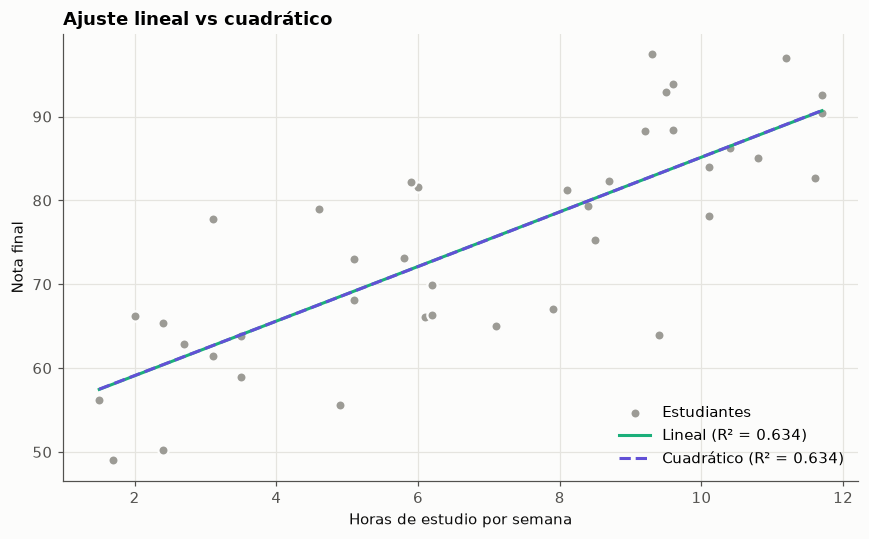

Lineal:     nota = 3.26·h + 52.57
Cuadrático: nota = 0.002·h² + 3.24·h + 52.63


In [17]:
# --- Verificación de seguridad: recrea el entorno si esta celda se ejecuta sola ---
if "df" not in globals() or "COLORES_ESTADO" not in globals():
    from pathlib import Path
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    from sklearn.metrics import r2_score

    NOTA_APROBATORIA = 60
    COLORES_ESTADO = {"aprobado": "#2a78d6", "en_riesgo": "#eb6834"}
    COLOR_LINEAL, COLOR_CUADRATICO = "#1baf7a", "#6250d6"
    COLOR_UMBRAL, COLOR_NEUTRO = "#52514e", "#9c9b95"
    plt.rcParams.update({
        "figure.figsize": (8, 5), "figure.dpi": 110,
        "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#e5e4df", "grid.linewidth": 0.8,
        "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
    })
    RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
    RUTA_CSV = RAIZ / "data" / "entrada" / "estudiantes.csv"
    if not RUTA_CSV.exists():
        raise FileNotFoundError(f"No existe {RUTA_CSV}. Ejecuta la primera celda o 'python main.py'.")
    df = pd.read_csv(RUTA_CSV, encoding="utf-8")

x = df["horas_estudio"].to_numpy()
y = df["nota_final"].to_numpy()

coef_lineal = np.polyfit(x, y, deg=1)
coef_cuadratico = np.polyfit(x, y, deg=2)

r2_lineal = r2_score(y, np.polyval(coef_lineal, x))
r2_cuadratico = r2_score(y, np.polyval(coef_cuadratico, x))

x_curva = np.linspace(x.min(), x.max(), 200)

fig, ax = plt.subplots()
ax.scatter(x, y, s=45, color=COLOR_NEUTRO, edgecolor="#fcfcfb", linewidth=1.5,
           label="Estudiantes", zorder=2)
ax.plot(x_curva, np.polyval(coef_lineal, x_curva), color=COLOR_LINEAL, linewidth=2,
        label=f"Lineal (R² = {r2_lineal:.3f})", zorder=3)
ax.plot(x_curva, np.polyval(coef_cuadratico, x_curva), color=COLOR_CUADRATICO, linewidth=2,
        linestyle="--", label=f"Cuadrático (R² = {r2_cuadratico:.3f})", zorder=3)

ax.set_title("Ajuste lineal vs cuadrático", loc="left", fontweight="bold")
ax.set_xlabel("Horas de estudio por semana")
ax.set_ylabel("Nota final")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("Lineal:     nota = {:.2f}·h + {:.2f}".format(*coef_lineal))
print("Cuadrático: nota = {:.3f}·h² + {:.2f}·h + {:.2f}".format(*coef_cuadratico))

## 4. Distribución de notas

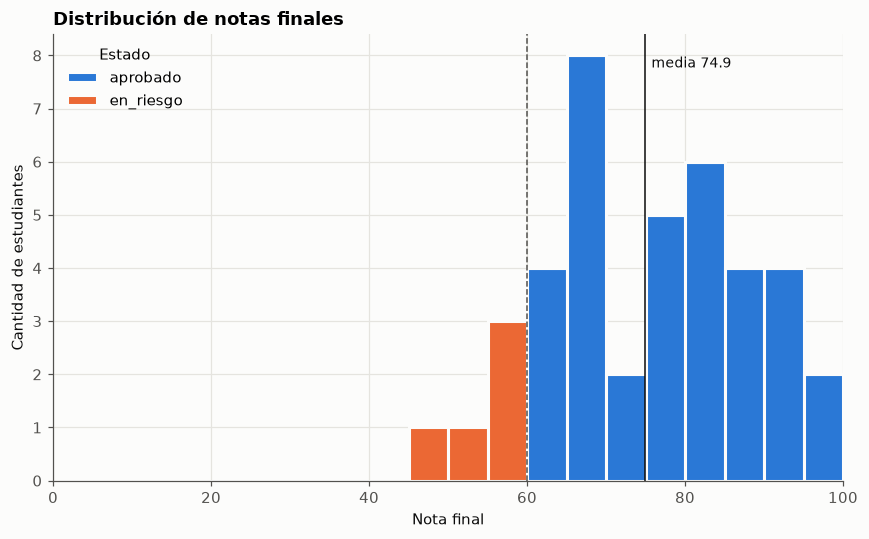

Porcentaje de estudiantes en riesgo: 12.5%


In [12]:
# --- Verificación de seguridad: recrea el entorno si esta celda se ejecuta sola ---
if "df" not in globals() or "COLORES_ESTADO" not in globals():
    from pathlib import Path
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    from sklearn.metrics import r2_score

    NOTA_APROBATORIA = 60
    COLORES_ESTADO = {"aprobado": "#2a78d6", "en_riesgo": "#eb6834"}
    COLOR_LINEAL, COLOR_CUADRATICO = "#1baf7a", "#6250d6"
    COLOR_UMBRAL, COLOR_NEUTRO = "#52514e", "#9c9b95"
    plt.rcParams.update({
        "figure.figsize": (8, 5), "figure.dpi": 110,
        "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#e5e4df", "grid.linewidth": 0.8,
        "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
    })
    RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
    RUTA_CSV = RAIZ / "data" / "entrada" / "estudiantes.csv"
    if not RUTA_CSV.exists():
        raise FileNotFoundError(f"No existe {RUTA_CSV}. Ejecuta la primera celda o 'python main.py'.")
    df = pd.read_csv(RUTA_CSV, encoding="utf-8")

bordes = np.arange(0, 105, 5)
media = df["nota_final"].mean()

fig, ax = plt.subplots()
ax.hist(
    [df.loc[df["estado"] == e, "nota_final"] for e in COLORES_ESTADO],
    bins=bordes, stacked=True, color=list(COLORES_ESTADO.values()),
    edgecolor="#fcfcfb", linewidth=2, label=list(COLORES_ESTADO), zorder=2,
)
ax.axvline(NOTA_APROBATORIA, color=COLOR_UMBRAL, linestyle="--", linewidth=1)
ax.axvline(media, color="#0b0b0b", linewidth=1)
ax.text(media + 0.8, ax.get_ylim()[1] * 0.95, f"media {media:.1f}",
        color="#0b0b0b", fontsize=9, va="top")

ax.set_title("Distribución de notas finales", loc="left", fontweight="bold")
ax.set_xlabel("Nota final")
ax.set_ylabel("Cantidad de estudiantes")
ax.set_xlim(0, 100)
ax.yaxis.get_major_locator().set_params(integer=True)
ax.legend(title="Estado", loc="upper left")
plt.tight_layout()
plt.show()

en_riesgo = (df["estado"] == "en_riesgo").mean() * 100
print(f"Porcentaje de estudiantes en riesgo: {en_riesgo:.1f}%")

## 5. Conclusiones

- Las horas de estudio tienen una relación positiva y casi lineal con la nota final, como se definió al generar los datos.
- Si el R² cuadrático apenas supera al lineal, el término cuadrático no aporta información real y el modelo lineal es preferible por simplicidad.
- El R² usando solo horas es menor que el de `LinearRegression` en `main.py`, porque la asistencia y las tareas también explican parte de la nota.
- Los estudiantes bajo el umbral de 60 son los candidatos a recibir una alerta académica.